# 03 — Comparaison des modèles MachineEar (Fan + Pump)

Ce notebook utilise le CSV produit par `01_data_preprocessing_8_machines.ipynb` et compare **Isolation Forest**, **One-Class SVM** et **Random Forest**.

Deux protocoles : **intra-machine** (entraînement/validation/test séparés pour un même ID) et **inter-machine** (test sur un ID totalement exclu de l'entraînement et de la validation). Les deux protocoles ne répondent pas à la même question. Random Forest est supervisé, les deux autres sont entraînés sur les seuls sons normaux. Le seuil est choisi uniquement sur la validation ; le test reste intact.

⚠️ La séparation par fichier n'empêche pas toutes les corrélations entre enregistrements d'une même session. Les résultats intra-machine sont exploratoires. L'inter-machine est plus exigeant.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, precision_score, recall_score, f1_score, roc_curve
import joblib

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "processed" / "fan_pump_all_features.csv"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True, parents=True)
RANDOM_STATE = 42
TARGET_FPR = 0.10  # objectif de fausses alertes sur validation normale
RUN_INTRA_MACHINE = True
RUN_CROSS_MACHINE = True
print('Dataset :', DATA_PATH)


Dataset : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\data\processed\fan_pump_all_features.csv


In [ ]:
if not DATA_PATH.exists():
    print('CSV disponibles :', list((ROOT / 'data' / 'processed').glob('*.csv')))
    raise FileNotFoundError(f"Fichier absent : {DATA_PATH}. Vérifier le nom de sortie du notebook 01.")
df = pd.read_csv(DATA_PATH)
required = {'file_path', 'machine_type', 'machine_id', 'label'}
assert required.issubset(df.columns), f"Colonnes absentes : {required - set(df.columns)}"
assert df['label'].isin([0,1]).all(), 'Labels attendus : 0 et 1'
assert not df['file_path'].duplicated().any(), 'Chemins audio dupliqués'
feature_cols = [c for c in df.columns if c.startswith('mfcc_') or c in {
    f'{k}_{stat}' for k in ('rms','zcr','centroid','bandwidth','rolloff','flatness') for stat in ('mean','std')}]
assert len(feature_cols) == 52, f"52 caractéristiques attendues, trouvé {len(feature_cols)}"
assert df[feature_cols].notna().all().all(), 'Caractéristiques manquantes'
assert np.isfinite(df[feature_cols].to_numpy(dtype=float)).all(), 'Valeurs infinies ou non finies'
print('Dimensions :', df.shape, '| Caractéristiques :', len(feature_cols))
display(pd.crosstab([df.machine_type, df.machine_id], df.label, margins=True))

Dimensions : (9755, 58) | Caractéristiques : 52


label                       0     1   All
machine_type machine_id                  
fan          id_00       1011   407  1418
             id_02       1016   359  1375
             id_04       1033   348  1381
             id_06       1015   361  1376
pump         id_00       1006   143  1149
             id_02       1005   111  1116
             id_04        702   100   802
             id_06       1036   102  1138
All                      7824  1931  9755

## Méthode d’évaluation

- Isolation Forest et One-Class SVM apprennent sur les **normaux de l'entraînement** seulement ; Random Forest apprend sur les deux classes.
- Normalisation (`StandardScaler`) ajustée sur les données d'entraînement seulement (normales seulement pour les méthodes one-class).
- Le **seuil** est calibré pour un FPR cible sur les **normaux de validation**, sans utiliser le test.
- ROC-AUC et PR-AUC utilisent les scores continus ; le rappel, F1 et FPR utilisent le seuil calibré.
- Le test inter-machine laisse un identifiant entier de côté et recommence pour chaque ID. Les résultats peuvent chuter fortement, c'est précisément ce qu'on cherche à mesurer.

In [3]:
def build_model(name):
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=3,
                                      class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE)
    if name == 'OneClassSVM':
        return make_pipeline(StandardScaler(), OneClassSVM(nu=0.05, gamma='scale'))
    if name == 'IsolationForest':
        return make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
    raise ValueError(name)

def train_and_score(name, train, val, test):
    Xtr, ytr = train[feature_cols], train.label.to_numpy()
    Xv, yv = val[feature_cols], val.label.to_numpy()
    Xt, yt = test[feature_cols], test.label.to_numpy()
    if name == 'RandomForest':
        if len(np.unique(ytr)) < 2: raise ValueError('RandomForest exige les deux classes')
        model = build_model(name)
        model.fit(Xtr, ytr)
        score = lambda x: model.predict_proba(x)[:, list(model.classes_).index(1)]
    else:
        model = build_model(name)
        normal = Xtr[ytr == 0]
        if len(normal) < 20: raise ValueError('Trop peu de normaux pour entraîner')
        model.fit(normal)
        # Score élevé = anomalie probable
        score = lambda x: -model.decision_function(x).ravel()
    val_scores = score(Xv)
    test_scores = score(Xt)
    val_norm = val_scores[yv == 0]
    if len(val_norm) < 10: raise ValueError('Trop peu de normaux en validation')
    # Seuil fixe obtenu sur la validation, indépendamment des labels anormaux
    threshold = float(np.quantile(val_norm, 1-TARGET_FPR))
    pred = (test_scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0,1]).ravel()
    result = dict(model=name, threshold=threshold, n_train=len(train), n_val=len(val), n_test=len(test),
                  roc_auc=roc_auc_score(yt,test_scores) if len(np.unique(yt))==2 else np.nan,
                  pr_auc=average_precision_score(yt,test_scores) if len(np.unique(yt))==2 else np.nan,
                  fpr=fp/(fp+tn) if fp+tn else np.nan,
                  recall_anomaly=recall_score(yt,pred,zero_division=0),
                  precision_anomaly=precision_score(yt,pred,zero_division=0),
                  f1_anomaly=f1_score(yt,pred,zero_division=0), TN=tn, FP=fp, FN=fn, TP=tp)
    return result

MODELS = ['IsolationForest','OneClassSVM','RandomForest']


## A — Comparaison intra-machine

Pour chaque machine, séparation stratifiée **60 % entraînement / 20 % validation / 20 % test**. Ce protocole suppose que les deux classes sont suffisamment représentées.

In [4]:
intra_rows = []
if RUN_INTRA_MACHINE:
    for (kind, mid), subset in df.groupby(['machine_type','machine_id']):
        counts = subset.label.value_counts()
        if set(counts.index) != {0,1} or counts.min() < 10:
            print('IGNORÉ : classes insuffisantes', kind, mid, counts.to_dict()); continue
        train_val, test = train_test_split(subset, test_size=0.20, stratify=subset.label, random_state=RANDOM_STATE)
        train, val = train_test_split(train_val, test_size=0.25, stratify=train_val.label, random_state=RANDOM_STATE)
        for name in MODELS:
            try:
                r = train_and_score(name,train,val,test)
                intra_rows.append(dict(experiment='intra_machine', machine_type=kind, machine_id=mid, **r))
            except Exception as e: print('ERREUR', kind,mid,name,str(e))
    intra = pd.DataFrame(intra_rows)
    if not intra.empty:
        display(intra[['machine_type','machine_id','model','roc_auc','pr_auc','fpr','recall_anomaly','f1_anomaly','TN','FP','FN','TP']].round(3))
        intra.to_csv(REPORTS / '03_intra_machine_results.csv', index=False)


,machine_type,machine_id,model,roc_auc,pr_auc,fpr,recall_anomaly,f1_anomaly,TN,FP,FN,TP
0,fan,id_00,IsolationForest,0.700,0.423,0.079,0.110,0.168,186,16,73,9
1,fan,id_00,OneClassSVM,0.796,0.699,0.074,0.439,0.541,187,15,46,36
2,fan,id_00,RandomForest,0.989,0.975,0.084,0.963,0.888,185,17,3,79
3,fan,id_02,IsolationForest,0.784,0.545,0.123,0.583,0.604,178,25,30,42
4,fan,id_02,OneClassSVM,0.824,0.736,0.099,0.583,0.627,183,20,30,42
5,fan,id_02,RandomForest,0.998,0.995,0.118,1.000,0.857,179,24,0,72
6,fan,id_04,IsolationForest,0.715,0.418,0.082,0.200,0.277,190,17,56,14
7,fan,id_04,OneClassSVM,0.916,0.761,0.077,0.571,0.635,191,16,30,40
8,fan,id_04,RandomForest,0.999,0.997,0.087,1.000,0.886,189,18,0,70
9,fan,id_06,IsolationForest,0.826,0.508,0.113,0.333,0.403,181,23,48,24


## B — Généralisation inter-machine (leave-one-ID-out)

Pour chaque catégorie, un ID entier est conservé comme **test externe**. Les trois autres IDs servent à l'entraînement et à la validation. Aucun fichier de l'ID test ne sert à ajuster le modèle, le scaler ou le seuil.

In [5]:
cross_rows = []
if RUN_CROSS_MACHINE:
    for kind, category in df.groupby('machine_type'):
        ids = sorted(category.machine_id.unique())
        if len(ids) < 2:
            print('IGNORÉ : moins de 2 IDs pour', kind); continue
        for heldout in ids:
            test = category[category.machine_id == heldout]
            pool = category[category.machine_id != heldout]
            if set(pool.label.unique()) != {0,1} or set(test.label.unique()) != {0,1}:
                print('IGNORÉ : classes manquantes', kind,heldout); continue
            if pool.label.value_counts().min() < 10:
                print('IGNORÉ : effectif trop faible', kind,heldout); continue
            train, val = train_test_split(pool, test_size=0.25, stratify=pool.label, random_state=RANDOM_STATE)
            for name in MODELS:
                try:
                    r = train_and_score(name,train,val,test)
                    cross_rows.append(dict(experiment='cross_machine', machine_type=kind, machine_id=heldout, **r))
                except Exception as e: print('ERREUR',kind,heldout,name,str(e))
    cross = pd.DataFrame(cross_rows)
    if not cross.empty:
        display(cross[['machine_type','machine_id','model','roc_auc','pr_auc','fpr','recall_anomaly','f1_anomaly','TN','FP','FN','TP']].round(3))
        cross.to_csv(REPORTS / '03_cross_machine_results.csv', index=False)


,machine_type,machine_id,model,roc_auc,pr_auc,fpr,recall_anomaly,f1_anomaly,TN,FP,FN,TP
0,fan,id_00,IsolationForest,0.626,0.360,0.448,0.661,0.477,558,453,138,269
1,fan,id_00,OneClassSVM,0.654,0.448,0.986,0.990,0.446,14,997,4,403
2,fan,id_00,RandomForest,0.556,0.348,0.996,1.000,0.447,4,1007,0,407
3,fan,id_02,IsolationForest,0.640,0.361,0.098,0.170,0.235,916,100,298,61
4,fan,id_02,OneClassSVM,0.724,0.462,0.091,0.315,0.401,924,92,246,113
5,fan,id_02,RandomForest,0.582,0.315,0.963,0.989,0.420,38,978,4,355
6,fan,id_04,IsolationForest,0.541,0.320,0.074,0.089,0.136,957,76,317,31
7,fan,id_04,OneClassSVM,0.563,0.392,0.044,0.299,0.419,988,45,244,104
8,fan,id_04,RandomForest,0.699,0.448,0.079,0.313,0.404,951,82,239,109
9,fan,id_06,IsolationForest,0.626,0.387,0.106,0.216,0.285,907,108,283,78


## C — Synthèse et visualisation

Les moyennes par machine donnent le même poids à chaque ID. Elles ne doivent pas être confondues avec une évaluation sur un ensemble d'audios regroupés.

,experiment,machine_type,model,roc_auc,pr_auc,fpr,recall_anomaly,f1_anomaly
0,cross_machine,fan,IsolationForest,0.608,0.357,0.182,0.284,0.283
1,cross_machine,fan,OneClassSVM,0.622,0.458,0.522,0.629,0.415
2,cross_machine,fan,RandomForest,0.532,0.353,0.759,0.814,0.418
3,cross_machine,pump,IsolationForest,0.563,0.224,0.544,0.744,0.274
4,cross_machine,pump,OneClassSVM,0.644,0.423,0.592,0.809,0.310
5,cross_machine,pump,RandomForest,0.791,0.474,0.714,0.951,0.346
6,intra_machine,fan,IsolationForest,0.756,0.474,0.099,0.307,0.363
7,intra_machine,fan,OneClassSVM,0.880,0.782,0.091,0.648,0.666
8,intra_machine,fan,RandomForest,0.996,0.992,0.105,0.991,0.868
9,intra_machine,pump,IsolationForest,0.881,0.498,0.085,0.622,0.526


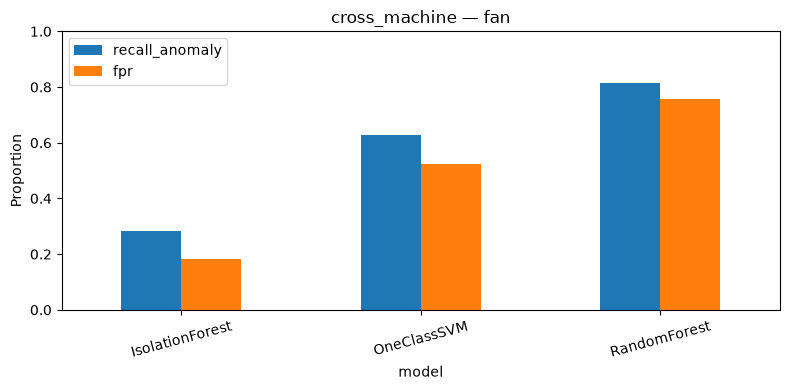

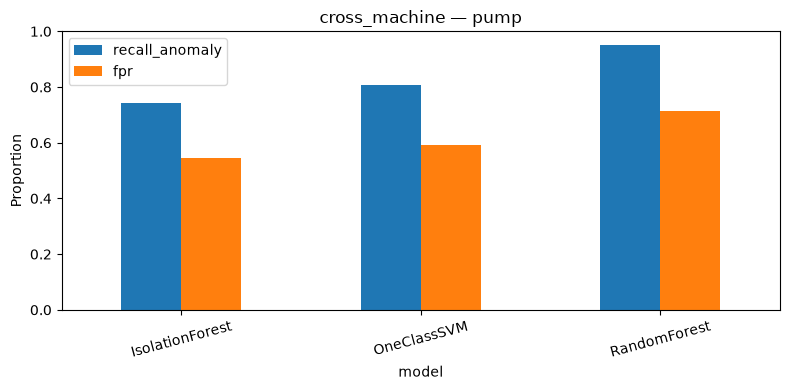

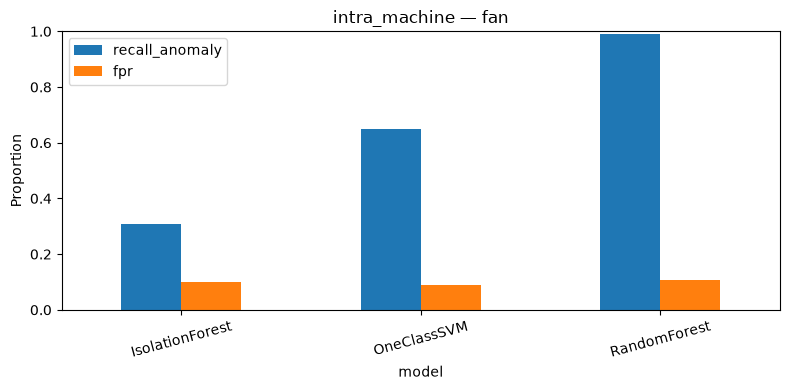

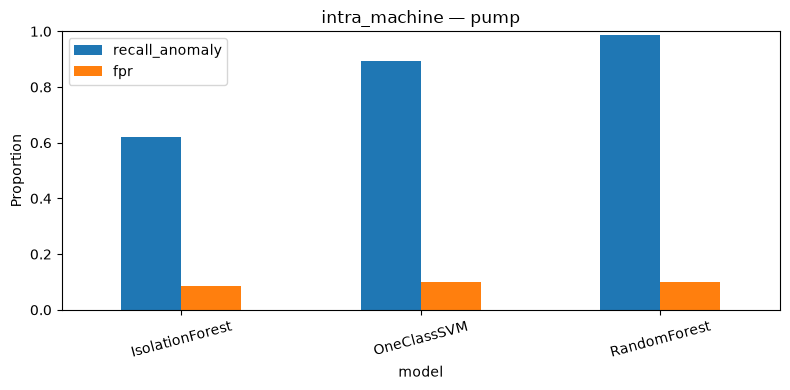

Résultats enregistrés dans : C:\Users\0503506P\Downloads\MachineEar_VSCode\MachineEar\reports


In [6]:
frames = []
if RUN_INTRA_MACHINE and intra_rows: frames.append(intra)
if RUN_CROSS_MACHINE and cross_rows: frames.append(cross)
if frames:
    results = pd.concat(frames, ignore_index=True)
    summary = results.groupby(['experiment','machine_type','model'], as_index=False)[['roc_auc','pr_auc','fpr','recall_anomaly','f1_anomaly']].mean()
    display(summary.round(3))
    summary.to_csv(REPORTS / '03_summary_results.csv',index=False)
    for (exp, kind), g in summary.groupby(['experiment','machine_type']):
        ax = g.set_index('model')[['recall_anomaly','fpr']].plot.bar(figsize=(8,4),rot=15,ylim=(0,1),title=f'{exp} — {kind}')
        ax.set_ylabel('Proportion')
        plt.tight_layout(); plt.show()
    print('Résultats enregistrés dans :', REPORTS)
else:
    print('Aucun résultat : vérifier la présence des deux classes par machine.')


## Lecture des résultats et prochaine étape

1. Examiner d'abord **cross_machine** : si les performances s'effondrent, le modèle mémorise peut-être des signatures spécifiques à chaque ID.
2. Comparer le **rappel** et le **FPR** : détecter plus d'anomalies peut entraîner davantage de fausses alertes.
3. **Ne pas choisir les hyperparamètres sur les IDs de test**. Pour un modèle final, définir à l'avance des IDs réservés au test et utiliser une validation interne sur les IDs restants.
4. Les trois algorithmes sont ici des références avec des hyperparamètres fixes ; ce notebook n'effectue **pas** de recherche exhaustive du meilleur modèle.
5. Les scores obtenus avec un entraînement sur un même ID ne sont pas directement comparables à une généralisation vers un ID jamais vu.

**Livrables** : `reports/03_intra_machine_results.csv`, `reports/03_cross_machine_results.csv`, `reports/03_summary_results.csv`.